## Import Libraries

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

## Configuration
Change only this cell when reusing the notebook for another pose.

In [2]:
POSE_NAME = "Vrikshasana"
MODEL_FILENAME = "vrikshasana_rf.pkl"

FEATURES = [
    "left_knee",
    "right_knee",
    "left_hip",
    "right_hip",
    "left_shoulder",
    "right_shoulder"
]

TARGET_COL = "target"
RANDOM_STATE = 42

## Load and Merge Datasets (Train / Val / Test)
Loads the pre-split correct/incorrect CSVs, merges them, and shuffles rows.

In [3]:
def load_and_merge(split_name):
    correct_path = f"{split_name}/correct_{split_name}.csv"
    incorrect_path = f"{split_name}/incorrect_{split_name}.csv"

    if not os.path.exists(correct_path) or not os.path.exists(incorrect_path):
        raise FileNotFoundError(
            f"Missing files for split '{split_name}'. "
            f"Expected: {correct_path} and {incorrect_path}"
        )

    correct_df = pd.read_csv(correct_path)
    incorrect_df = pd.read_csv(incorrect_path)

    df = pd.concat([correct_df, incorrect_df], ignore_index=True)
    df = df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

    return df

train_df = load_and_merge("train")
val_df   = load_and_merge("val")
test_df  = load_and_merge("test")

print("Train Shape :", train_df.shape)
print("Val Shape   :", val_df.shape)
print("Test Shape  :", test_df.shape)

Train Shape : (2530, 11)
Val Shape   : (542, 11)
Test Shape  : (543, 11)


## Sanity Checks

In [4]:
for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    missing = df[FEATURES + [TARGET_COL]].isnull().sum().sum()
    print(f"{name} missing values: {missing}")
    assert missing == 0, f"{name} split has missing values in required columns"

print("\nClass Distribution")
print("Train:\n", train_df[TARGET_COL].value_counts())
print("\nVal:\n", val_df[TARGET_COL].value_counts())
print("\nTest:\n", test_df[TARGET_COL].value_counts())

Train missing values: 0
Val missing values: 0
Test missing values: 0

Class Distribution
Train:
 target
0    1289
1    1241
Name: count, dtype: int64

Val:
 target
0    276
1    266
Name: count, dtype: int64

Test:
 target
0    277
1    266
Name: count, dtype: int64


## Feature / Target Split

In [5]:
X_train, y_train = train_df[FEATURES], train_df[TARGET_COL]
X_val,   y_val   = val_df[FEATURES],   val_df[TARGET_COL]
X_test,  y_test  = test_df[FEATURES],  test_df[TARGET_COL]

## Train Random Forest

In [6]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)

rf.fit(X_train, y_train)
print("Model Trained Successfully")

Model Trained Successfully


## Train vs Validation Accuracy (Overfitting Check)

In [7]:
train_pred = rf.predict(X_train)
val_pred   = rf.predict(X_val)

train_accuracy = accuracy_score(y_train, train_pred)
val_accuracy   = accuracy_score(y_val, val_pred)

print(f"Train Accuracy      : {train_accuracy*100:.2f}%")
print(f"Validation Accuracy : {val_accuracy*100:.2f}%")
print(f"Gap (Train - Val)   : {(train_accuracy - val_accuracy)*100:.2f}%")

if (train_accuracy - val_accuracy) > 0.10:
    print("Warning: large train-val gap, model may be overfitting")

print("\nValidation Classification Report")
print(classification_report(y_val, val_pred, target_names=["Incorrect", "Correct"]))

Train Accuracy      : 100.00%
Validation Accuracy : 100.00%
Gap (Train - Val)   : 0.00%

Validation Classification Report
              precision    recall  f1-score   support

   Incorrect       1.00      1.00      1.00       276
     Correct       1.00      1.00      1.00       266

    accuracy                           1.00       542
   macro avg       1.00      1.00      1.00       542
weighted avg       1.00      1.00      1.00       542



## Test Set Evaluation

In [8]:
test_pred = rf.predict(X_test)

test_accuracy  = accuracy_score(y_test, test_pred)
test_precision = precision_score(y_test, test_pred)
test_recall    = recall_score(y_test, test_pred)
test_f1        = f1_score(y_test, test_pred)

print(f"Test Accuracy  : {test_accuracy*100:.2f}%")
print(f"Test Precision : {test_precision*100:.2f}%")
print(f"Test Recall    : {test_recall*100:.2f}%")
print(f"Test F1 Score  : {test_f1*100:.2f}%")

print("\nFull Classification Report (Test)")
print(classification_report(y_test, test_pred, target_names=["Incorrect", "Correct"]))

Test Accuracy  : 100.00%
Test Precision : 100.00%
Test Recall    : 100.00%
Test F1 Score  : 100.00%

Full Classification Report (Test)
              precision    recall  f1-score   support

   Incorrect       1.00      1.00      1.00       277
     Correct       1.00      1.00      1.00       266

    accuracy                           1.00       543
   macro avg       1.00      1.00      1.00       543
weighted avg       1.00      1.00      1.00       543



Average confidence : 99.34%
Minimum confidence : 81.00%


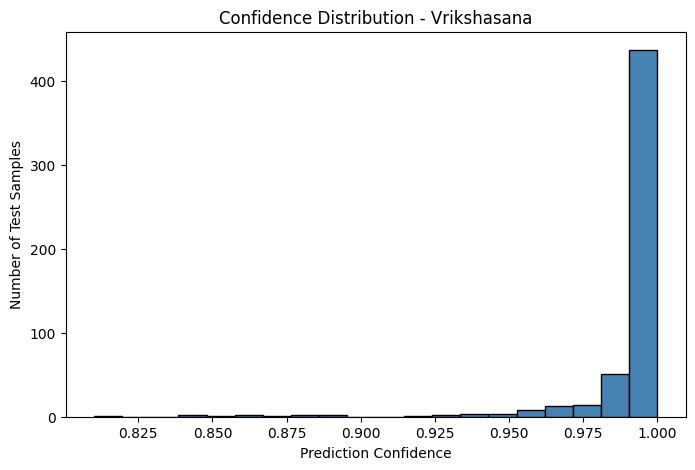

In [9]:
test_probs = rf.predict_proba(X_test)
test_confidence = test_probs.max(axis=1)  # confidence in whichever class was predicted

print(f"Average confidence : {test_confidence.mean()*100:.2f}%")
print(f"Minimum confidence : {test_confidence.min()*100:.2f}%")

plt.figure(figsize=(8, 5))
plt.hist(test_confidence, bins=20, color="steelblue", edgecolor="black")
plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Test Samples")
plt.title(f"Confidence Distribution - {POSE_NAME}")
plt.savefig(f"confidence_distribution_{POSE_NAME.lower().replace(' ', '_')}.png", dpi=150)
plt.show()

## Confusion Matrix

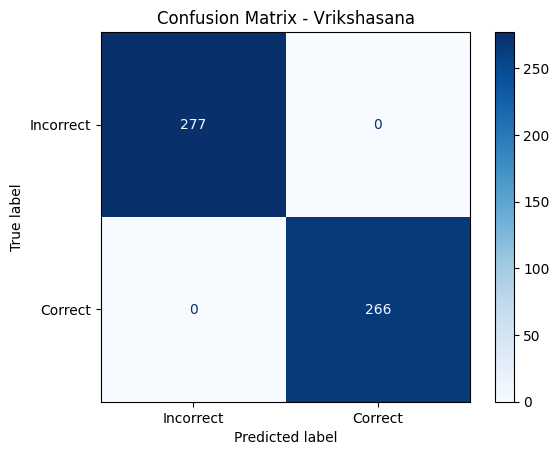

In [10]:
cm = confusion_matrix(y_test, test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Incorrect", "Correct"]
)

disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix - {POSE_NAME}")
plt.savefig(f"confusion_matrix_{POSE_NAME.lower().replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
plt.show()

## Feature Importance

          Feature  Importance
0       left_knee    0.254487
1      right_knee    0.205154
2  right_shoulder    0.168959
3   left_shoulder    0.147165
4       right_hip    0.133863
5        left_hip    0.090373


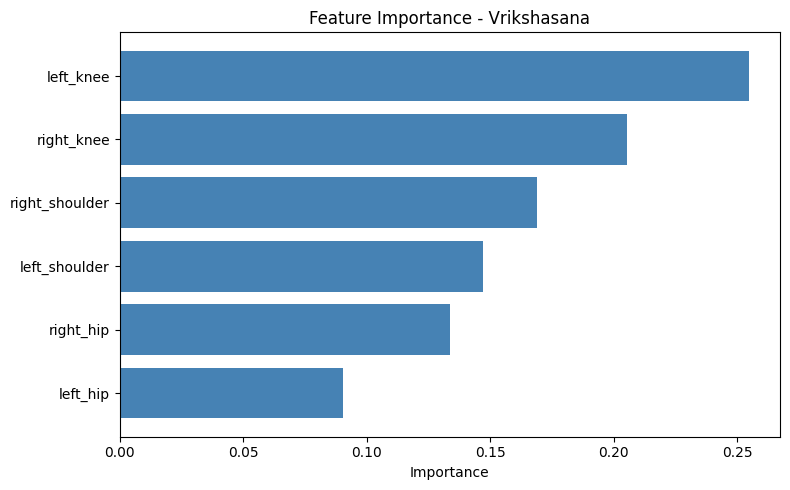

In [11]:
importance_df = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": rf.feature_importances_
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

print(importance_df)

plt.figure(figsize=(8, 5))
plt.barh(importance_df["Feature"], importance_df["Importance"], color="steelblue")
plt.xlabel("Importance")
plt.title(f"Feature Importance - {POSE_NAME}")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(f"feature_importance_{POSE_NAME.lower().replace(' ', '_')}.png", dpi=150)
plt.show()

## Save Model and Metadata

In [12]:
joblib.dump(rf, MODEL_FILENAME)

metadata = {
    "pose_name": POSE_NAME,
    "features": FEATURES,
    "target_mapping": {"0": "Incorrect", "1": "Correct"},
    "train_accuracy": round(train_accuracy, 4),
    "val_accuracy": round(val_accuracy, 4),
    "test_accuracy": round(test_accuracy, 4),
    "test_precision": round(test_precision, 4),
    "test_recall": round(test_recall, 4),
    "test_f1_score": round(test_f1, 4),
    "n_estimators": rf.n_estimators,
    "random_state": rf.random_state
}

metadata_filename = MODEL_FILENAME.replace(".pkl", "_metadata.json")
with open(metadata_filename, "w") as f:
    json.dump(metadata, f, indent=4)

print(f"Model saved as {MODEL_FILENAME}")
print(f"Metadata saved as {metadata_filename}")

Model saved as vrikshasana_rf.pkl
Metadata saved as vrikshasana_rf_metadata.json


## Test with One Sample

In [13]:
sample = X_test.iloc[[0]]

prediction = rf.predict(sample)[0]
probabilities = rf.predict_proba(sample)[0]
confidence = probabilities[prediction]

print("Prediction :", prediction)
print(f"{'Correct' if prediction == 1 else 'Incorrect'} {POSE_NAME}")
print(f"Confidence : {confidence*100:.2f}%")
print(f"  P(Incorrect) = {probabilities[0]*100:.2f}%")
print(f"  P(Correct)   = {probabilities[1]*100:.2f}%")

Prediction : 0
Incorrect Vrikshasana
Confidence : 100.00%
  P(Incorrect) = 100.00%
  P(Correct)   = 0.00%


## Data Cleaning Fix - Shoulder Angle Gap Violation

Official threshold table specifies shoulder angle must be either 3-50 deg (arms down) OR 150-180 deg (arms overhead) - the 51-149 deg range (horizontal/T-pose arms) should be Incorrect. Real-time testing showed the model almost entirely ignored shoulder angle (importance ~5.8% combined) because the Incorrect-class training data had only 2 examples in that gap - nowhere near enough to teach the model to reject it. Confirmed: horizontal arms + proper knee/hip leg lift still showed "Correct".

**Fix:** remove the few Correct-class rows already violating the gap rule, and add synthetic negative examples pairing realistic knee/hip values (sampled from real correct data) with shoulder angles drawn from the excluded 51-149 deg gap - teaching the model "good leg lift + bad arm position = still Incorrect".

**This section retrains and overwrites `vrikshasana_rf.pkl` / `vrikshasana_rf_metadata.json`. This is the final Vrikshasana model going forward.**

In [14]:
SHOULDER_GAP_MIN = 51
SHOULDER_GAP_MAX = 149

RAW_CORRECT_FILE = "../CSV/correct_vrikshasana (1).csv"
RAW_INCORRECT_FILE = "../CSV/incorrect_vrikshasana (1).csv"

def is_shoulder_gap_violation(df):
    return (
        (df["left_shoulder"].between(SHOULDER_GAP_MIN, SHOULDER_GAP_MAX)) |
        (df["right_shoulder"].between(SHOULDER_GAP_MIN, SHOULDER_GAP_MAX))
    )

raw_correct = pd.read_csv(RAW_CORRECT_FILE)
raw_incorrect = pd.read_csv(RAW_INCORRECT_FILE)

print(f"Before cleaning -> Correct: {raw_correct.shape} | Incorrect: {raw_incorrect.shape}")

gap_mask = is_shoulder_gap_violation(raw_correct)
removed_count = gap_mask.sum()
raw_correct_clean = raw_correct[~gap_mask].reset_index(drop=True)

print(f"Removed {removed_count} shoulder-gap-violating rows from 'Correct' class "
      f"({removed_count/len(raw_correct)*100:.1f}%)")

raw_correct_clean = raw_correct_clean.drop_duplicates(subset=FEATURES).reset_index(drop=True)
raw_incorrect_clean = raw_incorrect.drop_duplicates(subset=FEATURES).reset_index(drop=True)
print(f"After dedup -> Correct: {raw_correct_clean.shape} | Incorrect: {raw_incorrect_clean.shape}")

Before cleaning -> Correct: (1790, 11) | Incorrect: (1442, 11)
Removed 17 shoulder-gap-violating rows from 'Correct' class (0.9%)
After dedup -> Correct: (1773, 11) | Incorrect: (1442, 11)


### Add Synthetic Gap-Violation Negatives
Realistic knee/hip values (sampled from real Correct data) paired with shoulder angles drawn from the excluded 51-149 deg gap.

In [15]:
rng = np.random.default_rng(RANDOM_STATE)
N_SYNTHETIC = 400

sampled_base = raw_correct_clean.sample(n=N_SYNTHETIC, replace=True, random_state=RANDOM_STATE).reset_index(drop=True)

synthetic_gap = pd.DataFrame({
    "left_knee": sampled_base["left_knee"],
    "right_knee": sampled_base["right_knee"],
    "left_hip": sampled_base["left_hip"],
    "right_hip": sampled_base["right_hip"],
    "left_shoulder": rng.uniform(SHOULDER_GAP_MIN, SHOULDER_GAP_MAX, N_SYNTHETIC),
    "right_shoulder": rng.uniform(SHOULDER_GAP_MIN, SHOULDER_GAP_MAX, N_SYNTHETIC),
})
synthetic_gap[TARGET_COL] = 0

print(f"Added {N_SYNTHETIC} synthetic gap-violation examples to Incorrect class.")

raw_incorrect_clean = pd.concat([raw_incorrect_clean, synthetic_gap], ignore_index=True)
print(f"Incorrect class after synthetic addition: {raw_incorrect_clean.shape}")

Added 400 synthetic gap-violation examples to Incorrect class.
Incorrect class after synthetic addition: (1842, 11)


### Rebuild Clean Train/Val/Test Split

In [16]:
from sklearn.model_selection import train_test_split

def split_70_15_15(df, random_state=RANDOM_STATE):
    train, temp = train_test_split(df, test_size=0.30, random_state=random_state)
    val, test = train_test_split(temp, test_size=0.50, random_state=random_state)
    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)

correct_train_c, correct_val_c, correct_test_c = split_70_15_15(raw_correct_clean)
incorrect_train_c, incorrect_val_c, incorrect_test_c = split_70_15_15(raw_incorrect_clean)

for split in ["train", "val", "test"]:
    os.makedirs(split, exist_ok=True)

correct_train_c.to_csv("train/correct_train.csv", index=False)
incorrect_train_c.to_csv("train/incorrect_train.csv", index=False)
correct_val_c.to_csv("val/correct_val.csv", index=False)
incorrect_val_c.to_csv("val/incorrect_val.csv", index=False)
correct_test_c.to_csv("test/correct_test.csv", index=False)
incorrect_test_c.to_csv("test/incorrect_test.csv", index=False)

print("New split sizes:")
print("Train:", len(correct_train_c) + len(incorrect_train_c))
print("Val  :", len(correct_val_c) + len(incorrect_val_c))
print("Test :", len(correct_test_c) + len(incorrect_test_c))

New split sizes:
Train: 2530
Val  : 542
Test : 543


### Verify No Leakage

In [17]:
def load_merge_clean(split_name):
    c = pd.read_csv(f"{split_name}/correct_{split_name}.csv")
    i = pd.read_csv(f"{split_name}/incorrect_{split_name}.csv")
    return pd.concat([c, i], ignore_index=True)

train_df_c = load_merge_clean("train")
val_df_c = load_merge_clean("val")
test_df_c = load_merge_clean("test")

_train_set_c = set(map(tuple, train_df_c[FEATURES].round(4).values))
_val_set_c   = set(map(tuple, val_df_c[FEATURES].round(4).values))
_test_set_c  = set(map(tuple, test_df_c[FEATURES].round(4).values))

overlap_tv = len(_train_set_c & _val_set_c)
overlap_tt = len(_train_set_c & _test_set_c)
overlap_vt = len(_val_set_c & _test_set_c)

print("Train ∩ Val overlap :", overlap_tv)
print("Train ∩ Test overlap:", overlap_tt)
print("Val ∩ Test overlap  :", overlap_vt)

assert overlap_tv == 0
assert overlap_tt == 0
assert overlap_vt == 0
print("No leakage. Safe to train.")

Train ∩ Val overlap : 0
Train ∩ Test overlap: 0
Val ∩ Test overlap  : 0
No leakage. Safe to train.


### Retrain on Cleaned Data

In [18]:
X_train_c, y_train_c = train_df_c[FEATURES], train_df_c[TARGET_COL]
X_val_c,   y_val_c   = val_df_c[FEATURES],   val_df_c[TARGET_COL]
X_test_c,  y_test_c  = test_df_c[FEATURES],  test_df_c[TARGET_COL]

rf_clean = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)
rf_clean.fit(X_train_c, y_train_c)
print("Model trained on cleaned + gap-negative data.")

Model trained on cleaned + gap-negative data.


### Evaluate Cleaned Model

In [19]:
train_pred_c = rf_clean.predict(X_train_c)
val_pred_c   = rf_clean.predict(X_val_c)
test_pred_c  = rf_clean.predict(X_test_c)

train_accuracy_c = accuracy_score(y_train_c, train_pred_c)
val_accuracy_c   = accuracy_score(y_val_c, val_pred_c)
test_accuracy_c  = accuracy_score(y_test_c, test_pred_c)
test_precision_c = precision_score(y_test_c, test_pred_c)
test_recall_c    = recall_score(y_test_c, test_pred_c)
test_f1_c        = f1_score(y_test_c, test_pred_c)

print(f"Train Accuracy      : {train_accuracy_c*100:.2f}%")
print(f"Validation Accuracy : {val_accuracy_c*100:.2f}%")
print(f"Test Accuracy       : {test_accuracy_c*100:.2f}%")
print(f"Test Precision      : {test_precision_c*100:.2f}%")
print(f"Test Recall         : {test_recall_c*100:.2f}%")
print(f"Test F1             : {test_f1_c*100:.2f}%")

print("\nFull Classification Report (Test)")
print(classification_report(y_test_c, test_pred_c, target_names=["Incorrect", "Correct"]))

Train Accuracy      : 100.00%
Validation Accuracy : 100.00%
Test Accuracy       : 100.00%
Test Precision      : 100.00%
Test Recall         : 100.00%
Test F1             : 100.00%

Full Classification Report (Test)
              precision    recall  f1-score   support

   Incorrect       1.00      1.00      1.00       277
     Correct       1.00      1.00      1.00       266

    accuracy                           1.00       543
   macro avg       1.00      1.00      1.00       543
weighted avg       1.00      1.00      1.00       543



### Reproduce Failing Live-Test Screenshots
Confirms the retrained model now correctly rejects horizontal-arm poses while keeping genuine arms-overhead poses Correct.

In [20]:
test_cases = pd.DataFrame([
    {"name": "Horizontal arms + leg lift (was bug)",
     "left_knee": 46.5, "right_knee": 171.4, "left_hip": 115.4, "right_hip": 174.1,
     "left_shoulder": 74.4, "right_shoulder": 80.8},
    {"name": "Arms overhead + leg lift (genuine correct)",
     "left_knee": 45.5, "right_knee": 174.9, "left_hip": 120.2, "right_hip": 178.8,
     "left_shoulder": 179.7, "right_shoulder": 175.2},
])

for _, row in test_cases.iterrows():
    X_case = row[FEATURES].to_frame().T
    pred = rf_clean.predict(X_case)[0]
    proba = rf_clean.predict_proba(X_case)[0]
    label = "Correct" if pred == 1 else "Incorrect"
    print(f"{row['name']}: {label} (P(Incorrect)={proba[0]*100:.1f}%, P(Correct)={proba[1]*100:.1f}%)")

Horizontal arms + leg lift (was bug): Incorrect (P(Incorrect)=95.0%, P(Correct)=5.0%)
Arms overhead + leg lift (genuine correct): Correct (P(Incorrect)=29.0%, P(Correct)=71.0%)


### Confusion Matrix (Cleaned Model)

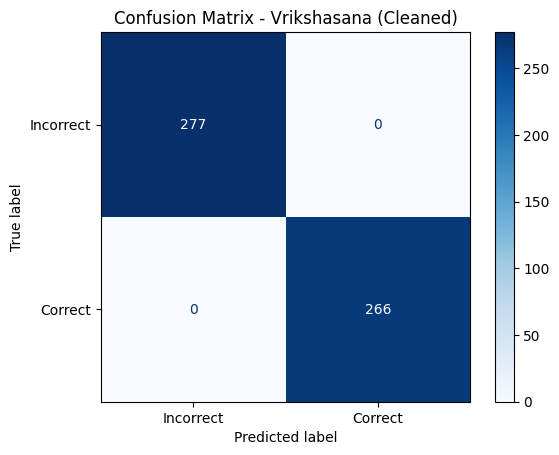

In [21]:
cm_c = confusion_matrix(y_test_c, test_pred_c)

disp_c = ConfusionMatrixDisplay(
    confusion_matrix=cm_c,
    display_labels=["Incorrect", "Correct"]
)

disp_c.plot(cmap="Blues")
plt.title(f"Confusion Matrix - {POSE_NAME} (Cleaned)")
plt.savefig(f"confusion_matrix_{POSE_NAME.lower()}_cleaned.png", dpi=150, bbox_inches="tight")
plt.show()

### Feature Importance (Cleaned Model)
Shoulder importance should now be meaningfully higher (previously near-negligible).

          Feature  Importance
0       left_knee    0.226405
1      right_knee    0.204820
2  right_shoulder    0.163708
3   left_shoulder    0.157351
4       right_hip    0.137033
5        left_hip    0.110684


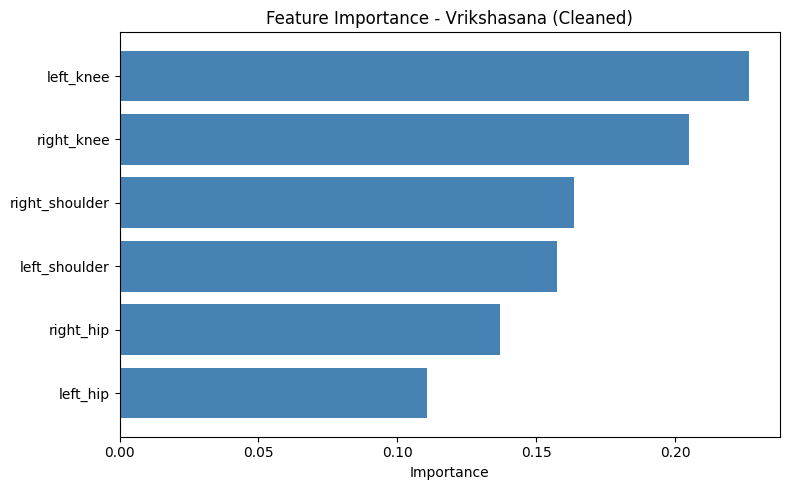

In [22]:
importance_df_c = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": rf_clean.feature_importances_
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

print(importance_df_c)

plt.figure(figsize=(8, 5))
plt.barh(importance_df_c["Feature"], importance_df_c["Importance"], color="steelblue")
plt.xlabel("Importance")
plt.title(f"Feature Importance - {POSE_NAME} (Cleaned)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(f"feature_importance_{POSE_NAME.lower()}_cleaned.png", dpi=150)
plt.show()

### Confidence (Cleaned Model)

Average confidence : 99.36%
Minimum confidence : 77.00%


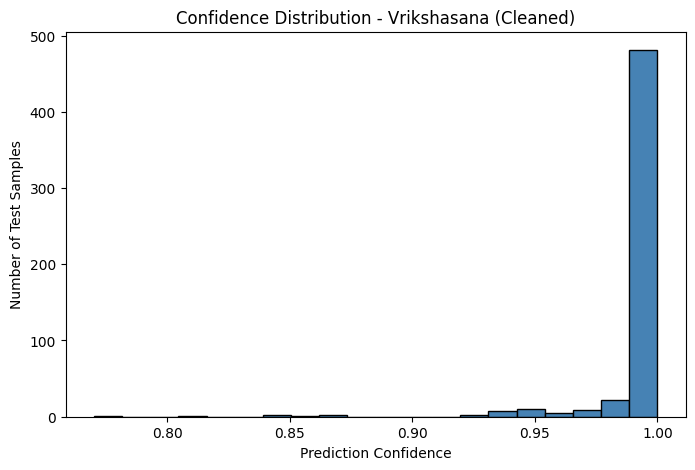

In [23]:
test_probs_c = rf_clean.predict_proba(X_test_c)
test_confidence_c = test_probs_c.max(axis=1)

print(f"Average confidence : {test_confidence_c.mean()*100:.2f}%")
print(f"Minimum confidence : {test_confidence_c.min()*100:.2f}%")

plt.figure(figsize=(8, 5))
plt.hist(test_confidence_c, bins=20, color="steelblue", edgecolor="black")
plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Test Samples")
plt.title(f"Confidence Distribution - {POSE_NAME} (Cleaned)")
plt.savefig(f"confidence_distribution_{POSE_NAME.lower()}_cleaned.png", dpi=150)
plt.show()

### Save Final Model and Metadata
**This overwrites `vrikshasana_rf.pkl` / `vrikshasana_rf_metadata.json` with the cleaned model. This is the final Vrikshasana model going forward.**

In [24]:
joblib.dump(rf_clean, MODEL_FILENAME)

metadata_c = {
    "pose_name": POSE_NAME,
    "features": FEATURES,
    "target_mapping": {"0": "Incorrect", "1": "Correct"},
    "train_accuracy": round(train_accuracy_c, 4),
    "val_accuracy": round(val_accuracy_c, 4),
    "test_accuracy": round(test_accuracy_c, 4),
    "test_precision": round(test_precision_c, 4),
    "test_recall": round(test_recall_c, 4),
    "test_f1_score": round(test_f1_c, 4),
    "n_estimators": rf_clean.n_estimators,
    "random_state": rf_clean.random_state,
    "data_cleaned": True,
    "note": f"Removed {removed_count} rows violating the official shoulder threshold (must be 3-50 or 150-180 deg) from Correct class. Added 400 synthetic negative examples pairing realistic knee/hip values with shoulder angles in the excluded 51-149 deg gap."
}

metadata_filename = MODEL_FILENAME.replace(".pkl", "_metadata.json")
with open(metadata_filename, "w") as f:
    json.dump(metadata_c, f, indent=4)

print(f"Model saved as {MODEL_FILENAME}")
print(f"Metadata saved as {metadata_filename}")
print("This is the final Vrikshasana model - correctly rejects horizontal-arm poses.")

Model saved as vrikshasana_rf.pkl
Metadata saved as vrikshasana_rf_metadata.json
This is the final Vrikshasana model - correctly rejects horizontal-arm poses.
